# Resource arithmetic and quantum-nuclear intuition

Original educational notebook. Read the linked course chapters. All synthetic models are labeled; no material property is inferred from a short run.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p/'scripts/numerics.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Extract the complete repository, then open this notebook from its root or notebooks folder.')
sys.path.insert(0, str(ROOT))
np.set_printoptions(precision=5)


## Resource worksheet
Only step/storage arithmetic is calculated. No hardware throughput is assumed.

Stride 100 raw GB for 3 replicas 180.0036
Stride 1000 raw GB for 3 replicas 18.0036
Stride 10000 raw GB for 3 replicas 1.8036


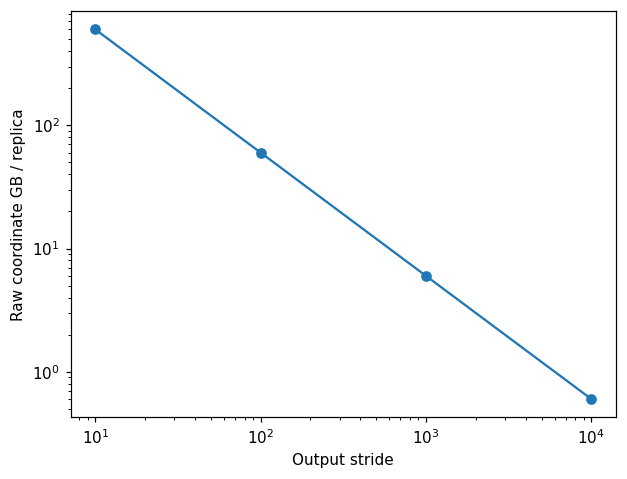

In [2]:
from scripts.resource_estimator import estimate
for stride in [100,1000,10000]:
    r=estimate(100000,10000,2,stride=stride,replicas=3)
    print('Stride',stride,'raw GB for 3 replicas',r['raw_coordinate_bytes_total']/1e9)
strides=np.array([10,100,1000,10000])
sizes=[estimate(100000,10000,2,stride=int(s))['raw_coordinate_bytes_total']/1e9 for s in strides]
plt.loglog(strides,sizes,'o-');plt.xlabel('Output stride');plt.ylabel('Raw coordinate GB / replica');plt.show()

## Separate physical exercise: quantum harmonic variance
PIMD targets equilibrium quantum statistics. In oscillator units, ⟨x²⟩/(ℏ/mω)=0.5 coth(βℏω/2). Classical statistics give 1/(βℏω). This analytical curve is not a PIMD simulation.

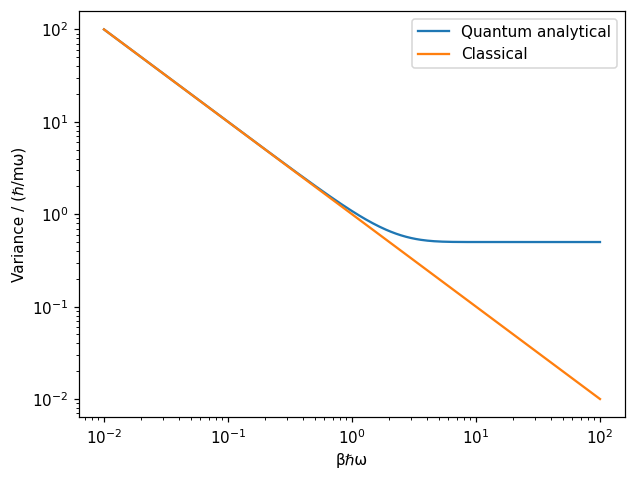

In [3]:
y=np.logspace(-2,2,300)
plt.loglog(y,.5/np.tanh(y/2),label='Quantum analytical')
plt.loglog(y,1/y,label='Classical')
plt.xlabel('βℏω');plt.ylabel('Variance / (ℏ/mω)');plt.legend();plt.show()

**Exercise:** state which resource costs multiply with bead count, and why bead velocities do not become exact quantum real-time velocities.